# Phase 2 — Probability and Probability Distributions

NHANES August 2021–August 2023: reported dietary supplement use and usual sleep duration among adults aged 20+. This notebook runs the analysis scripts, displays their final tables and figures, and links each visual to its interpretation in `reports/phase2/`. The main probability sample has **4,741** adults; different numerical summaries have documented complete-case counts.

In [1]:
from pathlib import Path
import subprocess
import sys
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "phase2_analysis.py").is_file())
OUT = ROOT / "data" / "processed" / "phase2"
FIGURES = ROOT / "figures" / "phase2"
print("Project:", ROOT)
print("Python:", sys.executable)

Project: /Users/ati.rap/Desktop/project_statistics
Python: /Users/ati.rap/Desktop/project_statistics/.venv/bin/python


## Rebuild the outputs

Both scripts read the original local XPT files and regenerate the CSV tables and PNG figures. The original data are never overwritten.

In [2]:
for script in ("phase2_analysis.py", "phase2_extended_analysis.py"):
    result = subprocess.run([sys.executable, str(ROOT / "src" / script)], cwd=ROOT,
                            capture_output=True, text=True, check=True)
    print(f"{script}: completed successfully")

phase2_analysis.py: completed successfully


phase2_extended_analysis.py: completed successfully


## 2.1–2.4 and 2.9 — Events, conditional probabilities, independence, and Bayes

`A`: reported any supplement use in the past 30 days. `B`: usual weekday sleep under 7 hours. All values in this section are unweighted empirical probabilities from the same 4,741 adults. The independence comparison and Bayes calculation reorganize the observed counts; they do not establish causation. See the corresponding English report sections for denominators and interpretation.

In [3]:
for filename in ("marginal_and_joint_probabilities.csv", "event_contingency_counts.csv",
                 "conditional_probabilities.csv", "independence_comparison.csv",
                 "bayes_reverse_conditional.csv"):
    print("\n", filename)
    display(pd.read_csv(OUT / filename).round(4))


 marginal_and_joint_probabilities.csv


,quantity,count,denominator_n,empirical_probability,percent
0,A: any supplement use,3070,4741,0.6475,64.7543
1,B: weekday sleep <7 hours,965,4741,0.2035,20.3544
2,A and B,546,4741,0.1152,11.5166



 event_contingency_counts.csv


,A_any_supplement,B complement: no,B: yes
0,A complement: no,1252,419
1,A: yes,2524,546



 conditional_probabilities.csv


,condition,group_n,under_7h_n,conditional_probability,percent
0,Any supplement use,3070,546,0.1779,17.7850
1,No supplement use,1671,419,0.2507,25.0748



 independence_comparison.csv


,analysis_n,p_a,p_b,observed_p_a_and_b,expected_p_a_and_b_if_independent,observed_minus_expected_percentage_points
0,4741,0.6475,0.2035,0.1152,0.1318,-1.6638



 bayes_reverse_conditional.csv


,analysis_n,supplement_users_n,short_sleep_n,both_n,prior_p_supplement,likelihood_p_short_given_supplement,evidence_p_short,posterior_p_supplement_given_short,p_supplement_given_not_short
0,4741,3070,965,546,0.6475,0.1779,0.2035,0.5658,0.6684


## 2.5 and Path A2 — A discrete count and the binomial model

A ten-person short-sleep count can be approximated with `Binomial(10, 546/3070)` when ten people are selected without replacement from the 3,070 observed supplement users; the exact distribution is hypergeometric. Path A2 randomly partitions all users into 307 non-overlapping ten-person groups. The plotted comparison is descriptive and depends on the fixed seed.

Ten-person count: binomial approximation vs exact without replacement


,k_short_sleepers,binomial_probability,exact_without_replacement_probability
0,0,0.141094,0.140647
1,1,0.305220,0.305340
2,2,0.297118,0.297634
3,3,0.171396,0.171541
4,4,0.064885,0.064736
5,5,0.016843,0.016715
6,6,0.003036,0.002990
7,7,0.000375,0.000366
8,8,0.000030,0.000029
9,9,0.000001,0.000001


Observed ten-person blocks vs binomial expected counts


,short_sleepers_k,observed_blocks,observed_fraction,binomial_probability,binomial_expected_blocks
0,0,43,0.1401,0.1411,43.3160
1,1,88,0.2866,0.3052,93.7026
2,2,103,0.3355,0.2971,91.2152
3,3,48,0.1564,0.1714,52.6186
4,4,19,0.0619,0.0649,19.9196
5,5,5,0.0163,0.0168,5.1709
6,6,0,0.0000,0.0030,0.9322
7,7,1,0.0033,0.0004,0.1152
8,8,0,0.0000,0.0000,0.0093
9,9,0,0.0000,0.0000,0.0004


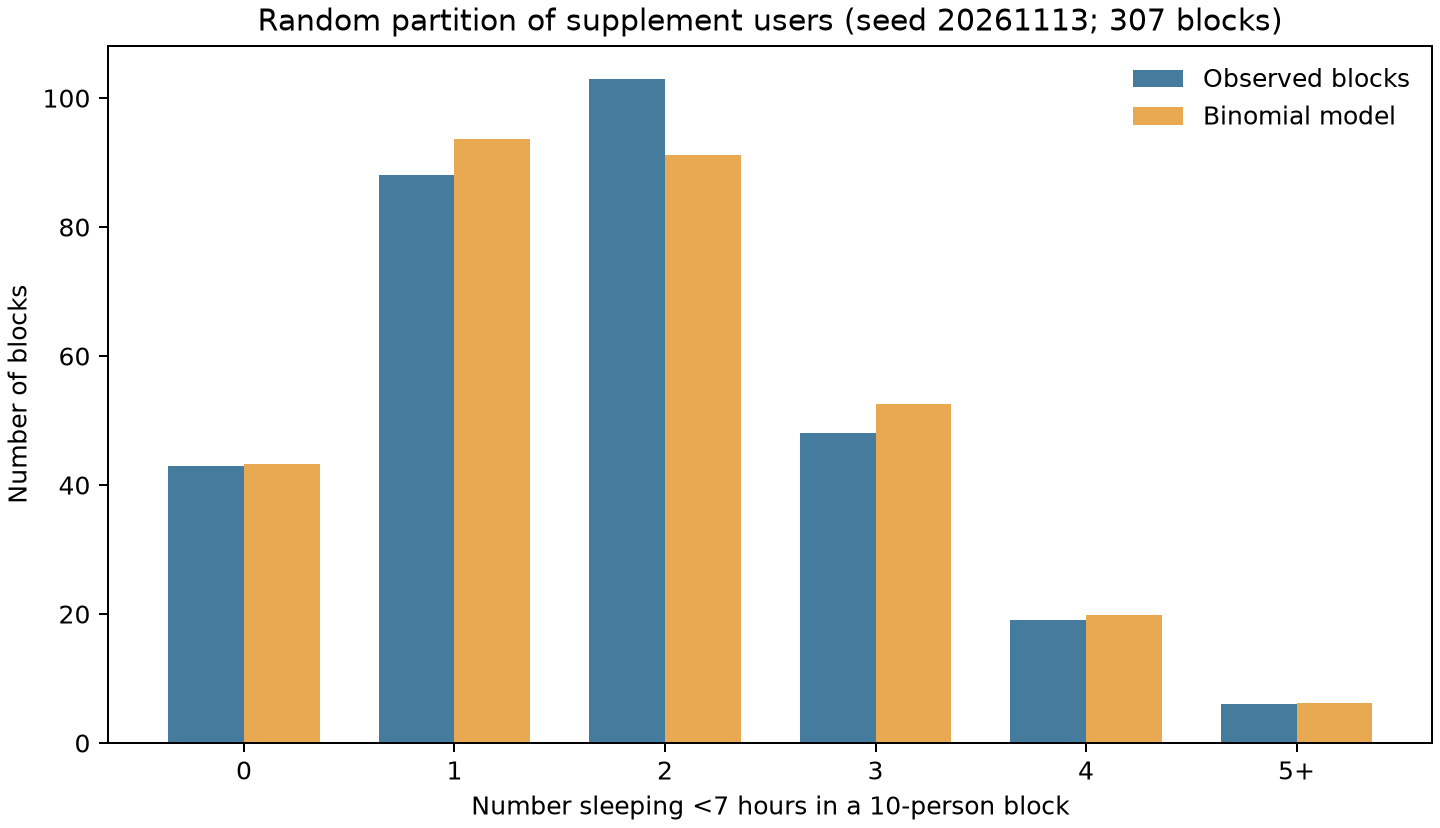

In [4]:
print("Ten-person count: binomial approximation vs exact without replacement")
display(pd.read_csv(OUT / "binomial_illustration.csv").round(6))
print("Observed ten-person blocks vs binomial expected counts")
display(pd.read_csv(OUT / "path_a2_equal_size_blocks.csv").round(4))
display(Image(filename=str(FIGURES / "fig1_binomial_blocks.png"), width=850))

## 2.6, 2.7, and Path A3 — Sleep duration, normal shape, mean, and variance

Usual weekday sleep is conceptually a duration, but NHANES releases rounded half-hour values. For numeric summaries and the normal comparison, the grouped endpoint codes `<3 hours` and `14+ hours` are excluded. These plots describe the 4,702 exact-hour responses. A smooth normal curve is only a rough visual reference.

,analysis_n,exact_weekday_hours_n,grouped_endpoint_excluded_n,mean_hours,empirical_variance_hours_squared,standard_deviation_hours,median_hours,sample_skewness,tukey_low_count,tukey_high_count
0,4741,4702,39,7.7084,2.113,1.4536,8.0,-0.1781,137,106


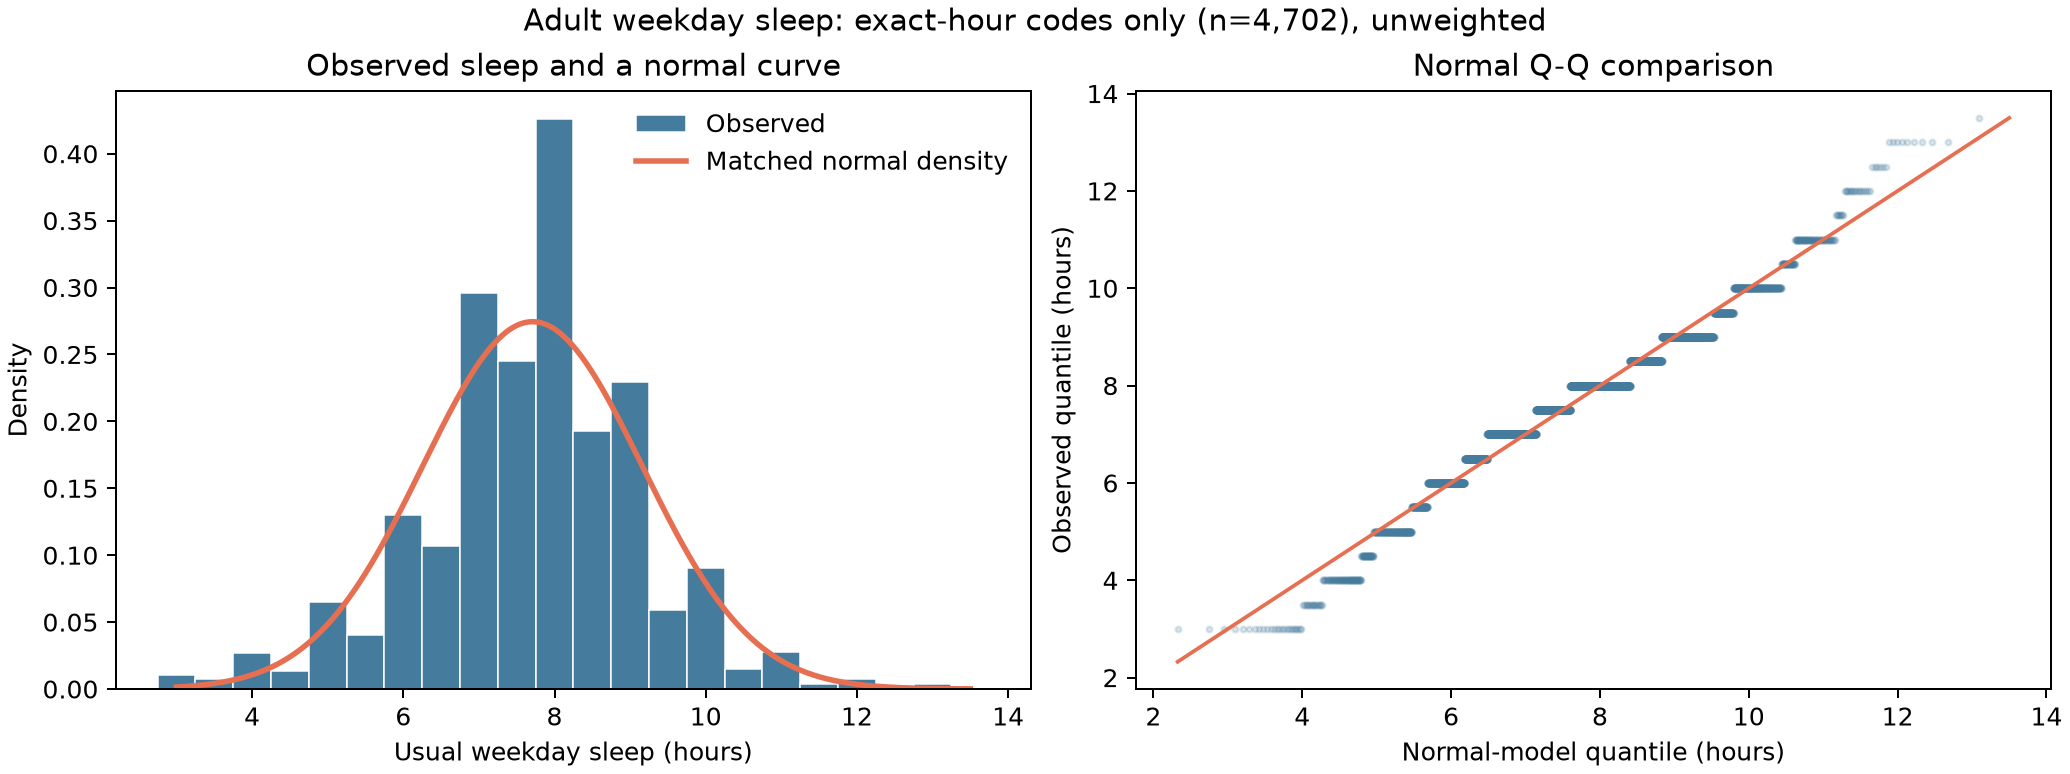

In [5]:
summary = pd.read_csv(OUT / "weekday_sleep_distribution_summary.csv")
columns = ["analysis_n", "exact_weekday_hours_n", "grouped_endpoint_excluded_n",
           "mean_hours", "empirical_variance_hours_squared", "standard_deviation_hours",
           "median_hours", "sample_skewness", "tukey_low_count", "tukey_high_count"]
display(summary[columns].round(4))
display(Image(filename=str(FIGURES / "fig2_weekday_sleep_normal_check.png"), width=1050))

## 2.8 — Paired weekday and weekend sleep

The same participant supplies both durations. Numeric covariance uses 4,669 adults with exact-hour codes for both measures; positive covariance means the two durations tend to move together in this sample. The hexbin display handles repeated half-hour pairs more clearly than an ordinary scatter plot.

,paired_n,weekday_mean_hours,weekend_mean_hours,empirical_covariance_hours_squared
0,4669,7.7081,8.2269,1.4279


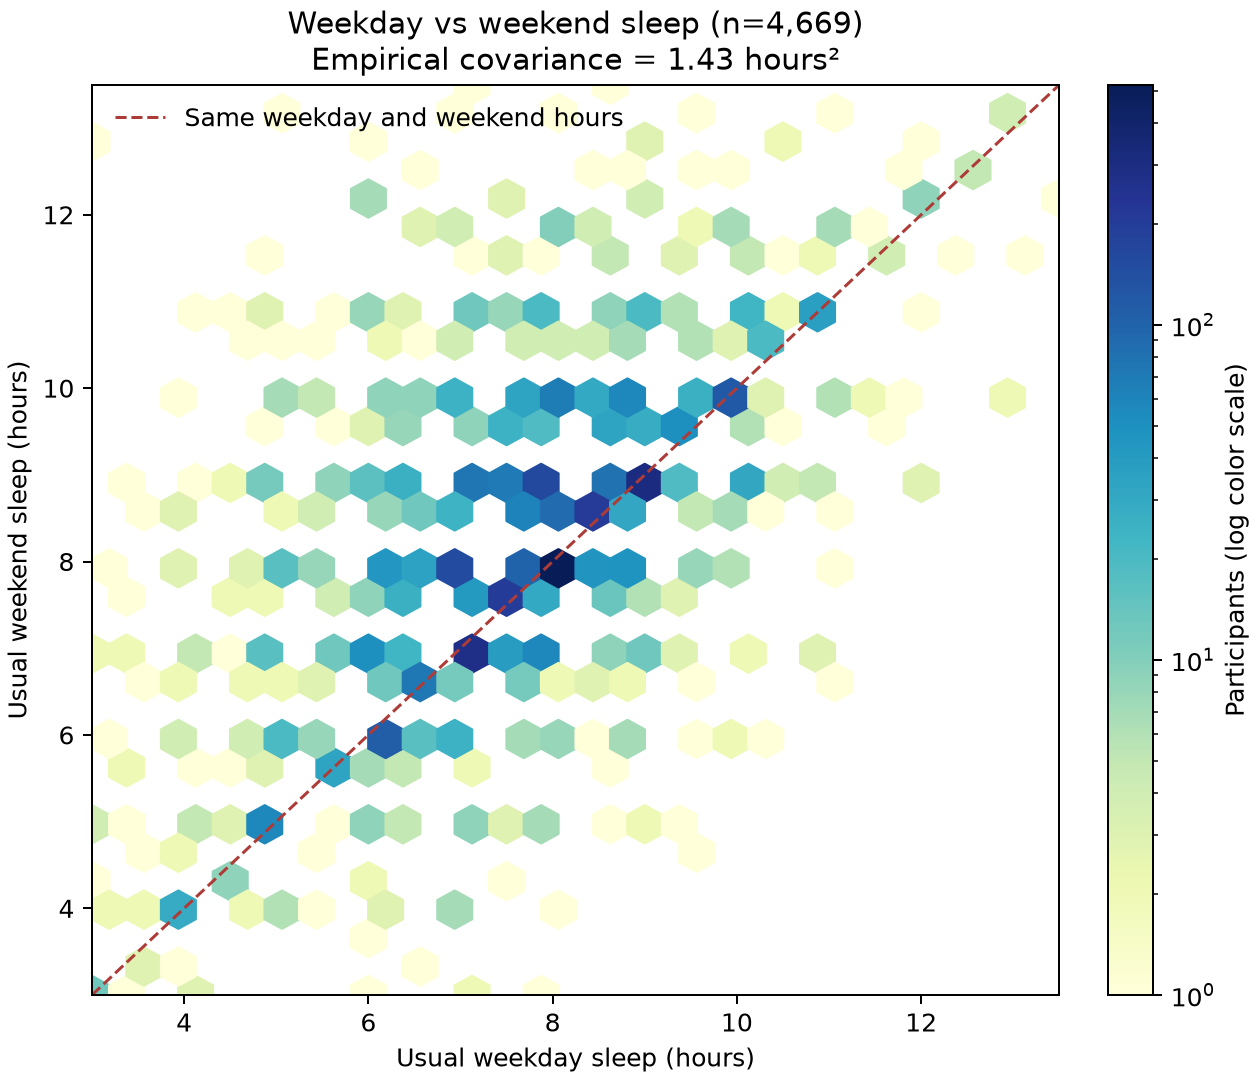

In [6]:
display(pd.read_csv(OUT / "weekday_weekend_covariance.csv").round(4))
display(Image(filename=str(FIGURES / "fig3_weekday_vs_weekend_sleep.png"), width=700))

## Path A1 — Conditional short-sleep probabilities by subgroup

Age bands and NHANES sex categories were set before viewing these results. Each row reports `P(B | supplement status, subgroup)` from the unweighted adult sample. These are descriptive comparisons without hypothesis tests.

In [7]:
subgroups = pd.read_csv(OUT / "path_a1_subgroup_conditional_probabilities.csv")
subgroups["short_sleep_percent"] = 100 * subgroups["short_sleep_probability"]
display(subgroups[["dimension", "subgroup", "supplement_use", "participants_n",
                   "short_sleep_n", "short_sleep_percent"]].round(2))

,dimension,subgroup,supplement_use,participants_n,short_sleep_n,short_sleep_percent
0,age_band,20-39,Yes,522,92,17.62
1,age_band,20-39,No,588,135,22.96
2,age_band,40-59,Yes,807,165,20.45
3,age_band,40-59,No,512,142,27.73
4,age_band,60+,Yes,1741,289,16.60
5,age_band,60+,No,571,142,24.87
6,sex,Male (code 1),Yes,1203,232,19.29
7,sex,Male (code 1),No,881,237,26.90
8,sex,Female (code 2),Yes,1867,314,16.82
9,sex,Female (code 2),No,790,182,23.04


## Path A4 — Raw and weighted empirical probability

The raw and `WTDRD1`-weighted percentages use the **same 4,737 positive-weight adults**. Weighting changes each respondent's contribution to the point estimate. Design-based standard errors would additionally need `SDMVSTRA` and `SDMVPSU`; this phase does not perform inference.

,group,participants_n,short_sleep_n,unweighted_percent,weighted_percent
0,All adults,4737,963,20.33,20.54
1,Supplement users,3068,544,17.73,17.57
2,Non-users,1669,419,25.10,25.04


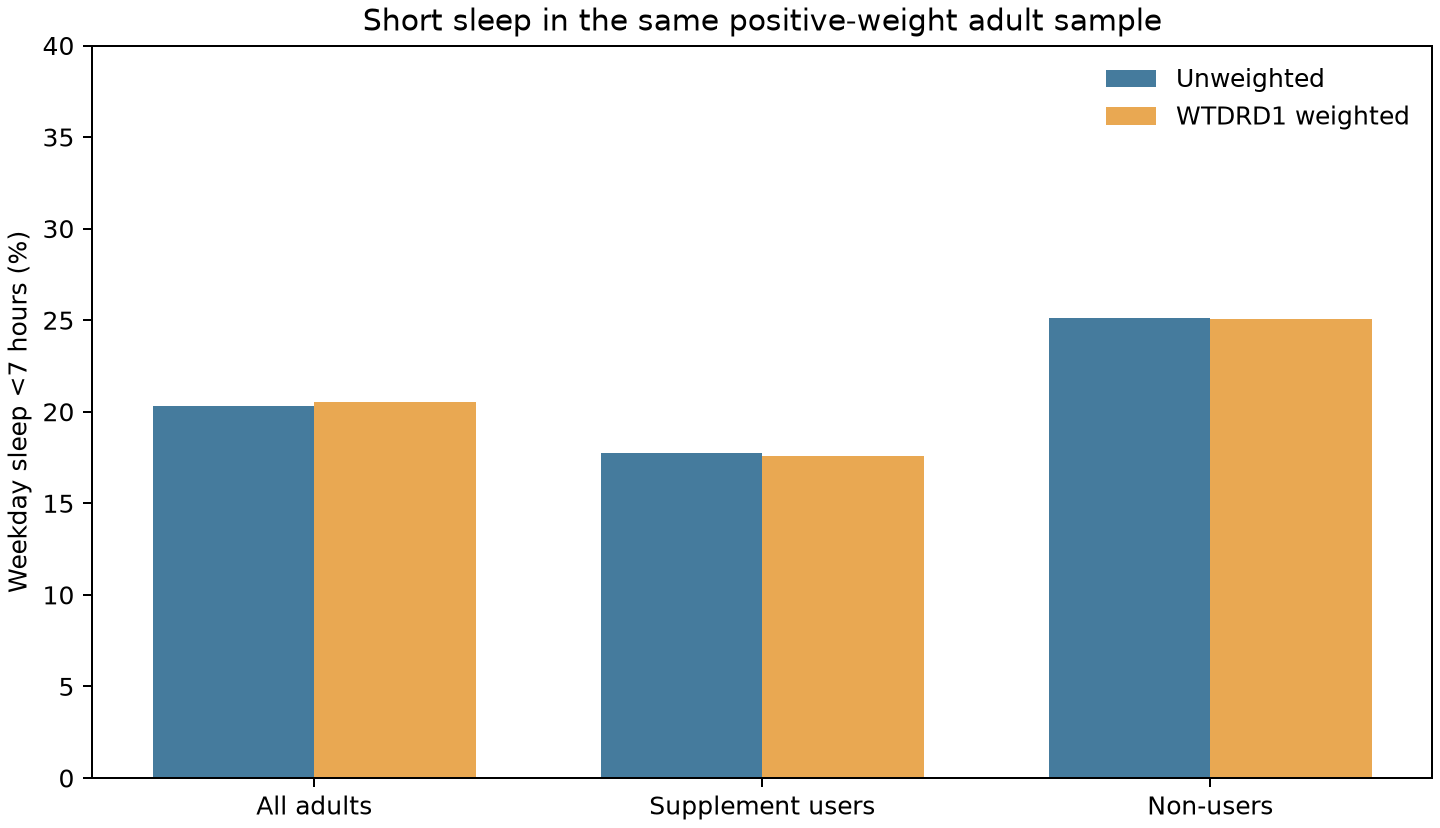

In [8]:
weighted = pd.read_csv(OUT / "path_a4_weighted_probability.csv")
weighted["unweighted_percent"] = 100 * weighted["unweighted_probability"]
weighted["weighted_percent"] = 100 * weighted["WTDRD1_weighted_probability"]
display(weighted[["group", "participants_n", "short_sleep_n",
                  "unweighted_percent", "weighted_percent"]].round(2))
display(Image(filename=str(FIGURES / "fig4_raw_vs_weighted_short_sleep.png"), width=850))

## Scope and interpretation

The survey is cross-sectional and observational. Supplement use groups many products together; reported sleep is rounded and self-reported. Unweighted proportions describe the retained sample. Weighted proportions are population-oriented point estimates for the eligible/responding component, with limitations from missing data. The full definitions, calculations, and caveats are in `reports/phase2/01_...md` through `09_...md` and `A1_...md` through `A4_...md`. Official CDC documentation is linked in `data/README.md`.